# Benchmarking Comparison

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 07.04.2026
- Date of Last Modification: 14.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk))

## 1. Setup

### 1.1 Load Libraries 

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from pathlib import Path

### 1.2 Define Config

In [45]:
# ---------------------------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------------------------
# Each method is paired with its corresponding embedding key
method_emb_pairs = [
    ("stjepa_v1",      "neighborhood_emb"),
    ("stjepa_v2",      "neighborhood_emb"),
    ("neigh_expr_pca", "X_pca"),
    #("nichecompass",    "nichecompass_latent"),
    ("cellcharter",    "X_cellcharter"),
    ("banksy",         "banksy_latent_harmony"),
    ("graphst",        "emb"),
    ("novae",          "novae_latent_corrected"),
    ("nicheformer",    "X_niche_embeddings"),
]

### 1.3 Configure Paths

In [46]:
base_path = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts/benchmarking")
results_dir = base_path / "results"
figures_dir = base_path / "figures"
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

### 1.4 Run Notebook Setup

In [50]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",  # export text as editable text in SVG
})

# Colour-blind friendly palette (Okabe-Ito + extras for 9 methods)
PALETTE = [
    "#0072B2",  # blue
    "#56B4E9",  # light blue
    "#009E73",  # green
    #"#E69F00",  # orange
    "#CC79A7",  # pink
    "#D55E00",  # red-orange
    "#F0E442",  # yellow
    "#8C564B",  # brown
    "#7F7F7F",  # grey
]

# Prettier method labels for the plot
METHOD_LABELS = {
    "stjepa_v1":      "ST-JEPA v1",
    "stjepa_v2":      "ST-JEPA v2",
    "neigh_expr_pca": "Neigh. Expr. PCA",
    #"nichecompass":    "NicheCompass",
    "cellcharter":    "CellCharter",
    "banksy":         "Banksy",
    "graphst":        "GraphST",
    "novae":          "Novae",
    "nicheformer":    "NicheFormer",
}

# Panel titles and ordering (MERFISH left, STARmap right)
REGION_TITLES = {
    "ccf_region_name":              "Tissue Regions (MERFISH)",
    "Sub_molecular_tissue_region":  "Tissue Regions (STARmap)",
}
REGION_ORDER = ["ccf_region_name", "Sub_molecular_tissue_region"]

### 1.5 Define Functions

In [66]:
def plot_metric_comparison(
    df: pd.DataFrame,
    metric: str,
    method_order: list[str],
    figsize_per_panel: tuple = (3.0, 2.4),
):
    """
    Bar plot of mean metric per method with individual data points overlaid.
    One panel per region_key. Text exported as editable paths for Illustrator.
    """
    region_keys = REGION_ORDER
    n_panels = len(region_keys)
    fig, axes = plt.subplots(
        1, n_panels,
        figsize=(figsize_per_panel[0] * n_panels, figsize_per_panel[1]),
        sharey=True,
        constrained_layout=True,
    )
    if n_panels == 1:
        axes = [axes]

    n_methods = len(method_order)
    bar_width = 0.6
    colors = PALETTE[:n_methods]

    for ax, rk in zip(axes, region_keys):
        sub = df[df["region_key"] == rk]

        means, sds, all_vals = [], [], []
        for m in method_order:
            vals = sub.loc[sub["method"] == m, metric].values
            means.append(np.mean(vals) if len(vals) > 0 else 0)
            sds.append(np.std(vals) if len(vals) > 0 else 0)
            all_vals.append(vals)

        x = np.arange(n_methods)

        # --- bars (mean) ---
        ax.bar(
            x, means, width=bar_width,
            color=colors, edgecolor="white", linewidth=0.6,
            alpha=0.75, zorder=2,
        )

        # --- error bars (± 1 SD) ---
        ax.errorbar(
            x, means, yerr=sds,
            fmt="none", ecolor="0.25", elinewidth=0.8,
            capsize=2.5, capthick=0.8, zorder=3,
        )

        # --- individual data points (jittered strip) ---
        rng = np.random.default_rng(42)
        for i, vals in enumerate(all_vals):
            n_pts = len(vals)
            if n_pts == 0:
                continue
            jitter = rng.uniform(-0.15, 0.15, size=n_pts)
            ax.scatter(
                np.full(n_pts, i) + jitter, vals,
                s=12, color="0.15", edgecolor="white",
                linewidth=0.3, zorder=4, alpha=0.65,
            )

        # --- dotted reference line at STJEPA v2 level ---
        if "stjepa_v2" in method_order:
            stjepa_idx = method_order.index("stjepa_v2")
            ax.axhline(y=means[stjepa_idx], color="0.3", linestyle="--",
                       linewidth=0.8, zorder=1, alpha=0.7)

        # --- formatting ---
        pretty_rk = REGION_TITLES.get(rk, rk.replace("_", " "))
        ax.set_title(pretty_rk, fontweight="medium")
        ax.set_xticks(x)
        ax.set_xticklabels(
            [METHOD_LABELS.get(m, m) for m in method_order],
            rotation=45, ha="right",
        )
        ax.tick_params(axis="x", pad=1)
        ax.set_ylabel(f"{metric} (\u2191)" if ax is axes[0] else "")
        ax.set_xlim(-0.5, n_methods - 0.5)
        ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
        ax.grid(axis="y", linewidth=0.3, alpha=0.5)

    return fig

## 2. Analysis

=== Data points per (method, region_key) ===
region_key      Sub_molecular_tissue_region  ccf_region_name
method                                                      
banksy                                    9                9
cellcharter                               9                9
graphst                                   9                9
neigh_expr_pca                            9                9
nicheformer                               9                9
novae                                     9                9
stjepa_v1                                 9                9
stjepa_v2                                 9                9

Saved combined dataframe to /nfs/team361/sb75/stjepa-reproducibility/artifacts/benchmarking/results/niche_identification_all_methods.csv

Saved niche_NMI_comparison.svg / .pdf / .png
Saved niche_ARI_comparison.svg / .pdf / .png


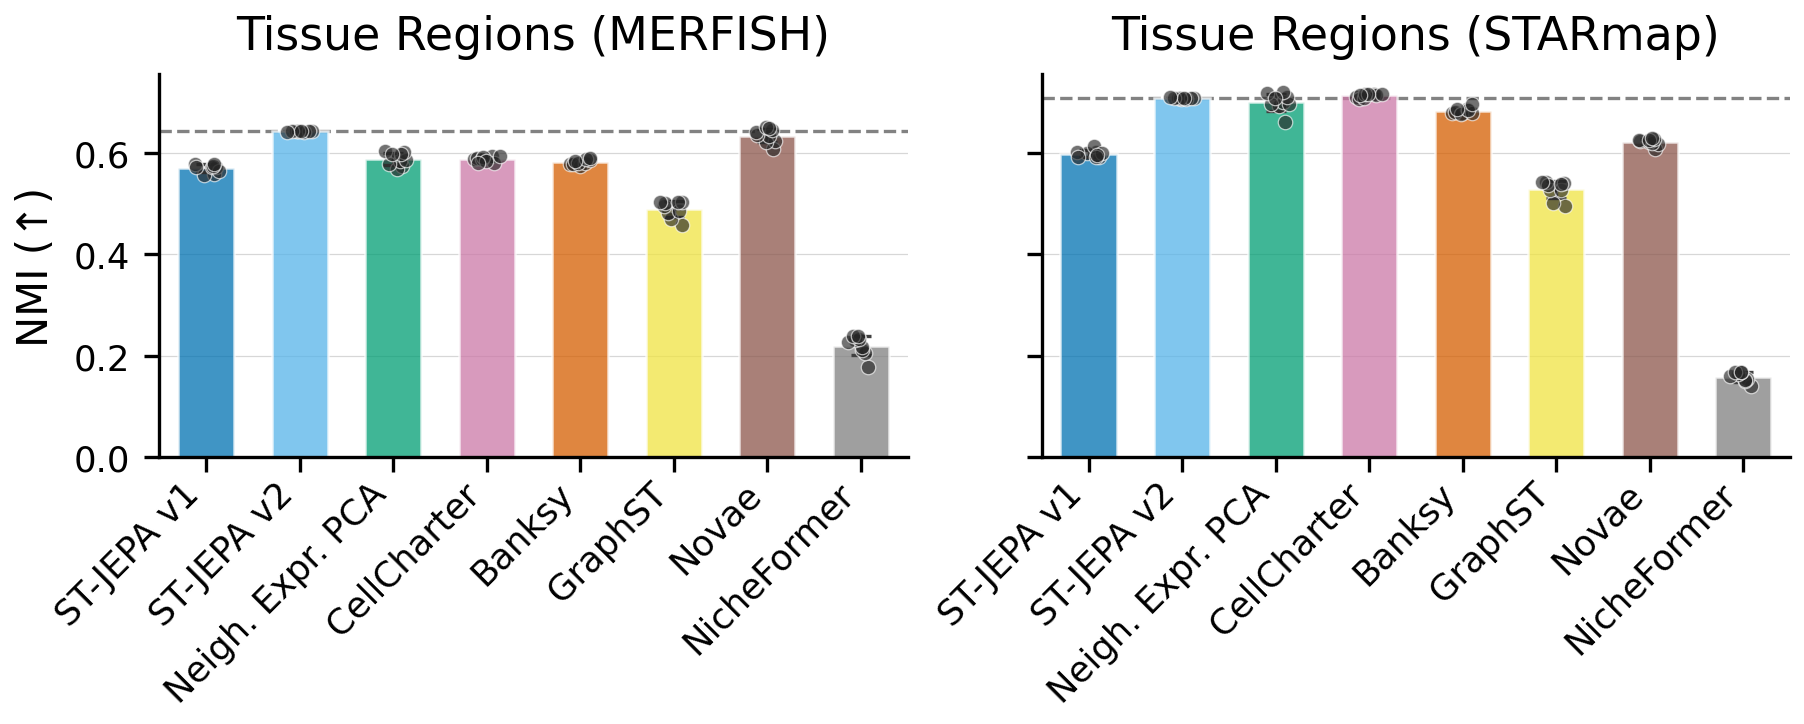

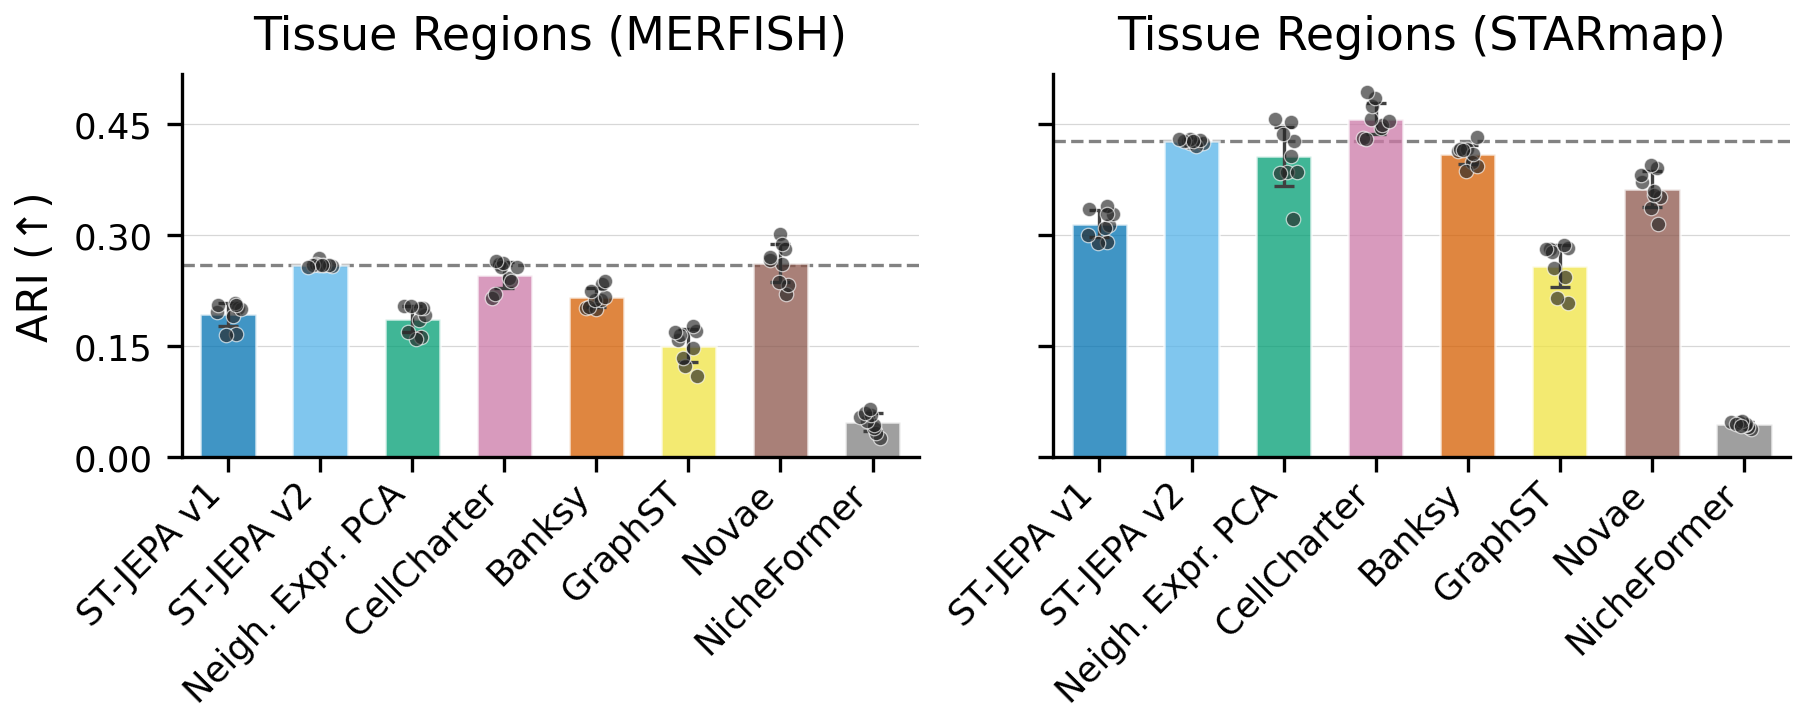

In [67]:
# ---------------------------------------------------------------------------
# 1. Load and concatenate all CSV files
# ---------------------------------------------------------------------------
frames = []
for method, emb_key in method_emb_pairs:
    fpath = (
        base_path / method
        / f"mmb0-1b_smb1-1b_1p_{emb_key}_niche_identification_metrics_res_sweep.csv"
    )
    if not fpath.exists():
        print(f"[WARN] File not found, skipping: {fpath}")
        continue
    df = pd.read_csv(fpath)
    df["method"] = method
    df["emb_key"] = emb_key
    frames.append(df)

if not frames:
    raise FileNotFoundError("No CSV files were found. Check your paths.")

df_all = pd.concat(frames, ignore_index=True)

# Sanity check: print counts per method and region_key
print("=== Data points per (method, region_key) ===")
print(df_all.groupby(["method", "region_key"]).size().unstack(fill_value=0))
print()

# Save combined dataframe
df_all.to_csv(results_dir / "niche_identification_all_methods.csv", index=False)
print(f"Saved combined dataframe to {results_dir / 'niche_identification_all_methods.csv'}\n")

# ---------------------------------------------------------------------------
# 2. Generate and save figures
# ---------------------------------------------------------------------------
method_order = [m for m, _ in method_emb_pairs]

for metric in ["NMI", "ARI"]:
    fig = plot_metric_comparison(df_all, metric=metric, method_order=method_order)
    for ext in ["svg", "pdf", "png"]:
        out = figures_dir / f"niche_{metric}_comparison.{ext}"
        fig.savefig(out)
    print(f"Saved niche_{metric}_comparison.svg / .pdf / .png")

plt.show()

Saved weighted results to /nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/results/weighted_niche_identification_all_methods.csv

Saved niche_weighted_NMI_comparison.svg / .pdf / .png
Saved niche_weighted_ARI_comparison.svg / .pdf / .png


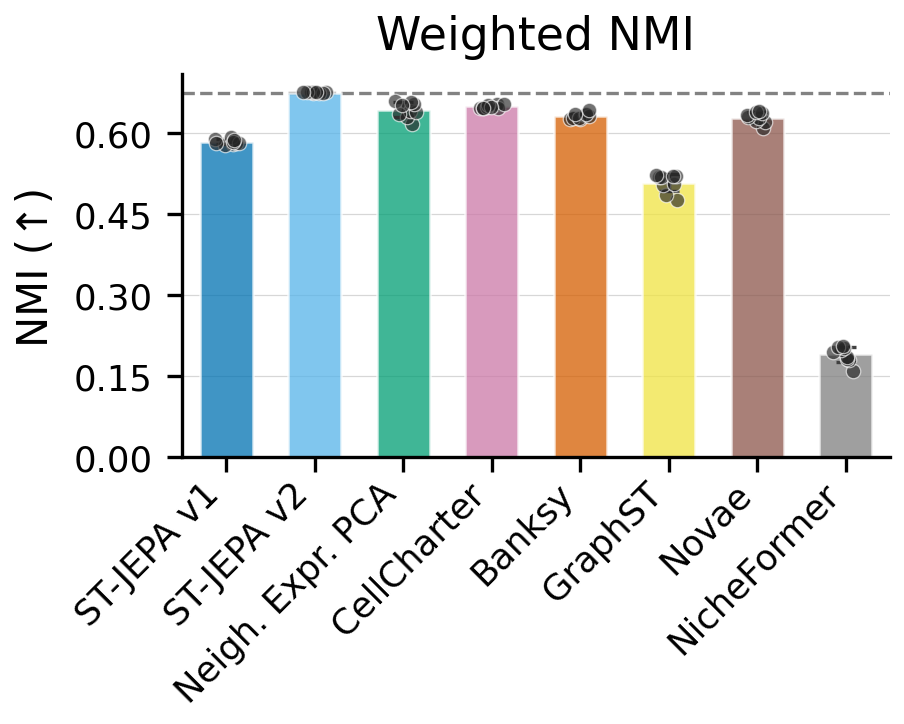

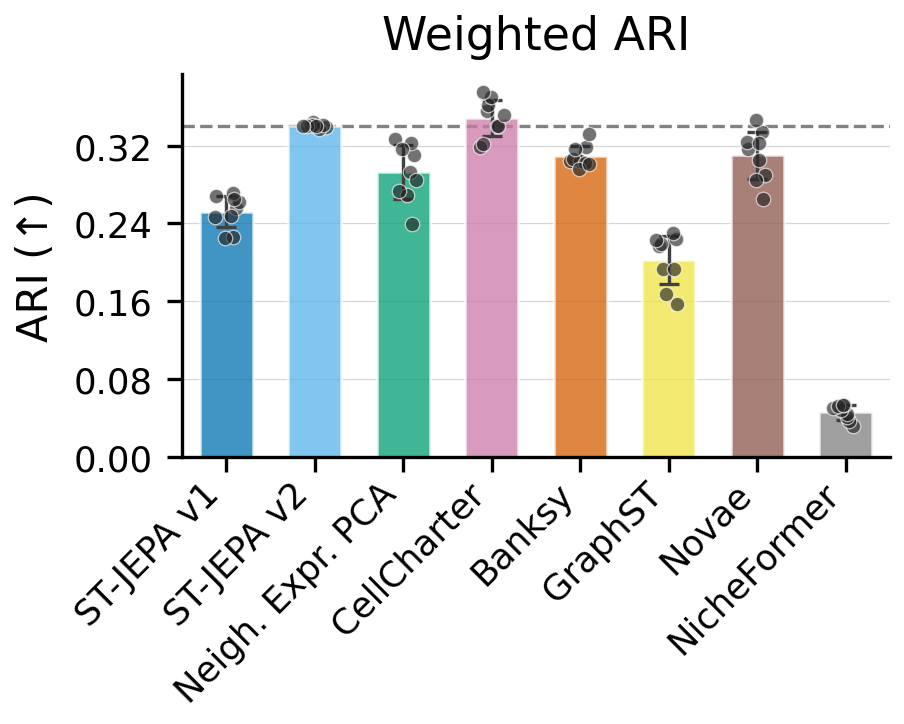

In [70]:
# ---------------------------------------------------------------------------
# Weighted average NMI/ARI across datasets (weighted by number of cells)
# ---------------------------------------------------------------------------

CELL_COUNTS = {
    "Sub_molecular_tissue_region": 42136,  # STARmap
    "ccf_region_name": 44686,              # MERFISH
}

total_cells = sum(CELL_COUNTS.values())
WEIGHTS = {rk: n / total_cells for rk, n in CELL_COUNTS.items()}

def plot_weighted_metric(
    df: pd.DataFrame,
    metric: str,
    method_order: list[str],
    figsize: tuple = (3.0, 2.4),
):
    """
    Vertical bar plot of weighted average metric across datasets,
    with individual per-resolution data points overlaid.
    """
    n_methods = len(method_order)
    bar_width = 0.6
    colors = PALETTE[:n_methods]

    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)

    # Compute weighted mean and SD per method
    means, sds, all_vals = [], [], []
    for m in method_order:
        weighted_vals = []
        for _, row in df[df["method"] == m].iterrows():
            rk = row["region_key"]
            w = WEIGHTS.get(rk, 0.5)
            weighted_vals.append(row[metric] * w)

        # Group by resolution to get one weighted value per resolution
        sub = df[df["method"] == m]
        resolutions = sub["resolution"].unique()
        res_weighted = []
        for res in resolutions:
            res_sub = sub[sub["resolution"] == res]
            val = 0
            for rk, w in WEIGHTS.items():
                rk_vals = res_sub.loc[res_sub["region_key"] == rk, metric].values
                if len(rk_vals) > 0:
                    val += rk_vals[0] * w
            res_weighted.append(val)

        res_weighted = np.array(res_weighted)
        means.append(np.mean(res_weighted) if len(res_weighted) > 0 else 0)
        sds.append(np.std(res_weighted) if len(res_weighted) > 0 else 0)
        all_vals.append(res_weighted)

    x = np.arange(n_methods)

    # --- bars (mean) ---
    ax.bar(
        x, means, width=bar_width,
        color=colors, edgecolor="white", linewidth=0.6,
        alpha=0.75, zorder=2,
    )

    # --- error bars (± 1 SD) ---
    ax.errorbar(
        x, means, yerr=sds,
        fmt="none", ecolor="0.25", elinewidth=0.8,
        capsize=2.5, capthick=0.8, zorder=3,
    )

    # --- individual data points (jittered strip) ---
    rng = np.random.default_rng(42)
    for i, vals in enumerate(all_vals):
        n_pts = len(vals)
        if n_pts == 0:
            continue
        jitter = rng.uniform(-0.15, 0.15, size=n_pts)
        ax.scatter(
            np.full(n_pts, i) + jitter, vals,
            s=12, color="0.15", edgecolor="white",
            linewidth=0.3, zorder=4, alpha=0.65,
        )

    # --- dotted reference line at STJEPA v2 level ---
    if "stjepa_v2" in method_order:
        stjepa_idx = method_order.index("stjepa_v2")
        ax.axhline(y=means[stjepa_idx], color="0.3", linestyle="--",
                   linewidth=0.8, zorder=1, alpha=0.7)

    # --- formatting ---
    ax.set_title(f"Weighted {metric}", fontweight="medium")
    ax.set_xticks(x)
    ax.set_xticklabels(
        [METHOD_LABELS.get(m, m) for m in method_order],
        rotation=45, ha="right",
    )
    ax.tick_params(axis="x", pad=1)
    ax.set_ylabel(f"{metric} (\u2191)")
    ax.set_xlim(-0.5, n_methods - 0.5)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)

    return fig


# ---------------------------------------------------------------------------
# Generate and save weighted figures
# ---------------------------------------------------------------------------
method_order = [m for m, _ in method_emb_pairs]

# Compute and save weighted metrics to CSV
weighted_rows = []
for metric in ["NMI", "ARI"]:
    for m in method_order:
        sub = df_all[df_all["method"] == m]
        resolutions = sub["resolution"].unique()
        for res in resolutions:
            res_sub = sub[sub["resolution"] == res]
            val = 0
            for rk, w in WEIGHTS.items():
                rk_vals = res_sub.loc[res_sub["region_key"] == rk, metric].values
                if len(rk_vals) > 0:
                    val += rk_vals[0] * w
            weighted_rows.append({
                "method": m,
                "resolution": res,
                "metric": metric,
                "weighted_score": val,
            })

df_weighted = pd.DataFrame(weighted_rows)
weighted_results_dir = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/results")
weighted_results_dir.mkdir(parents=True, exist_ok=True)
df_weighted.to_csv(weighted_results_dir / "weighted_niche_identification_all_methods.csv", index=False)
print(f"Saved weighted results to {weighted_results_dir / 'weighted_niche_identification_all_methods.csv'}\n")

for metric in ["NMI", "ARI"]:
    fig = plot_weighted_metric(df_all, metric=metric, method_order=method_order)
    for ext in ["svg", "pdf", "png"]:
        out = figures_dir / f"niche_weighted_{metric}_comparison.{ext}"
        fig.savefig(out)
    print(f"Saved niche_weighted_{metric}_comparison.svg / .pdf / .png")

plt.show()

Saved batch integration dataframe to /nfs/team361/sb75/stjepa-reproducibility/artifacts/benchmarking/results/batch_integration_all_methods.csv

Saved batch_integration_iLISI.svg / .pdf / .png
Saved batch_integration_ASW.svg / .pdf / .png
Saved batch_integration_MMD.svg / .pdf / .png


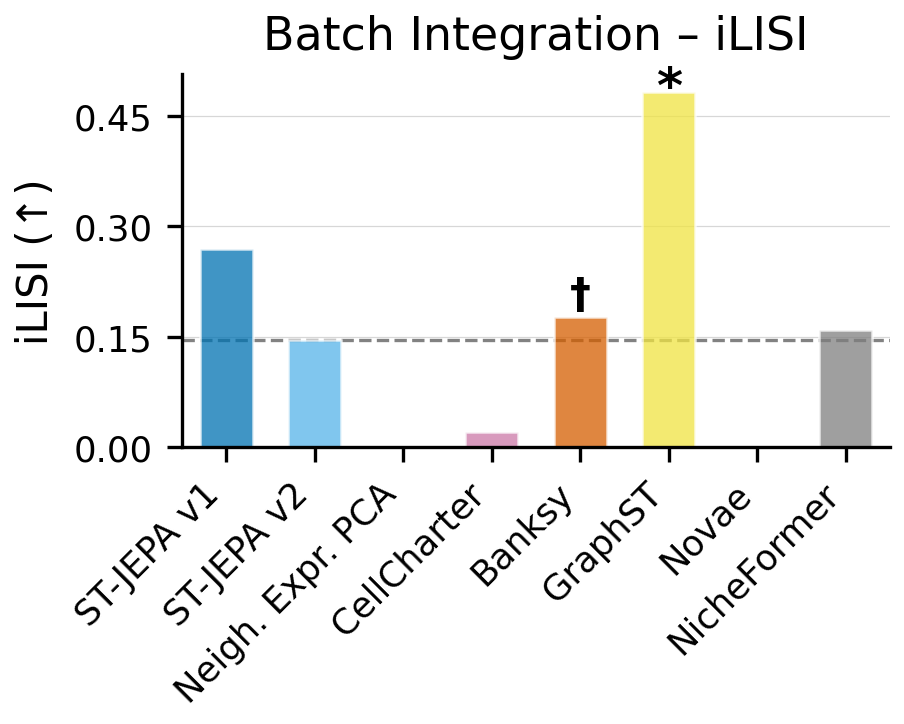

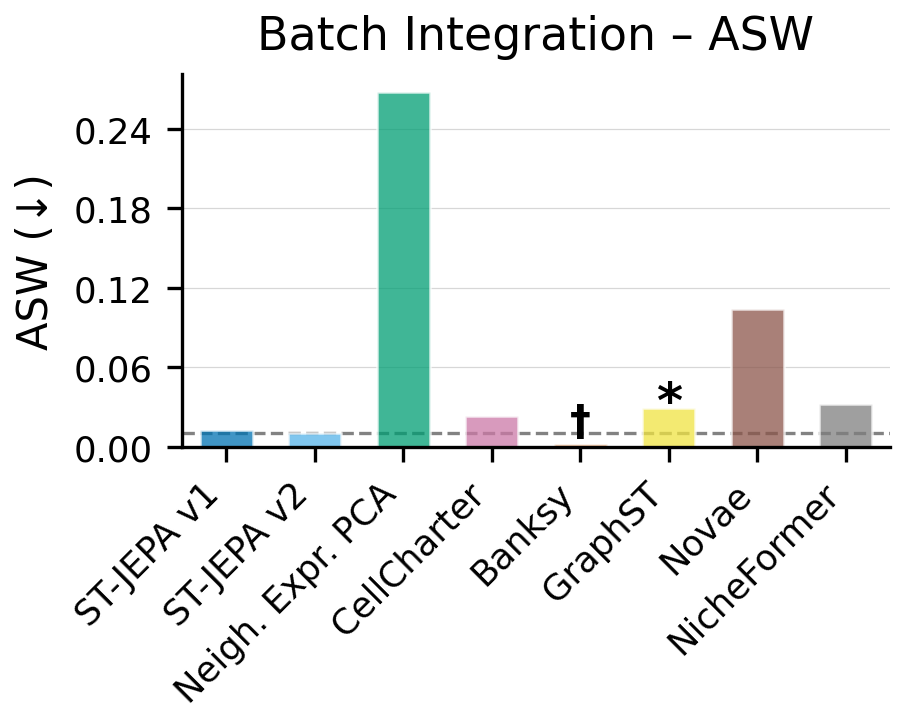

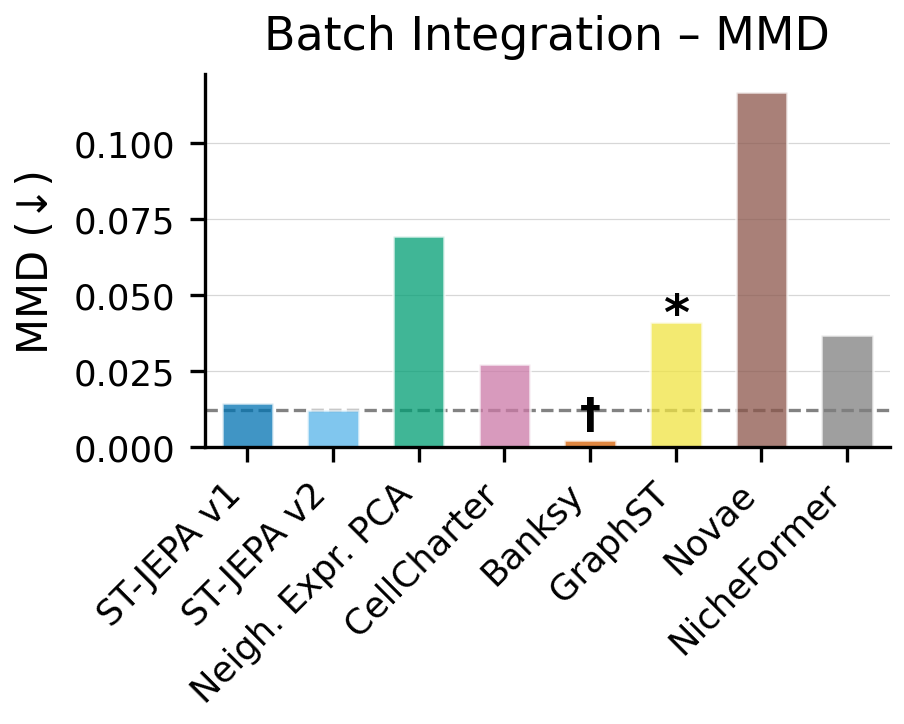

In [68]:
# ---------------------------------------------------------------------------
# Batch integration benchmarking – vertical bar plot (matching niche ID style)
# ---------------------------------------------------------------------------

BATCH_METRIC_DIRECTION = {
    "iLISI": "\u2191",
    "ASW":   "\u2193",
    "MMD":   "\u2193",
}

# Load batch integration CSVs
batch_frames = []
for method, emb_key in method_emb_pairs:
    fpath = (
        base_path / method
        / f"mmb0-1b_smb1-1b_1p_{emb_key}_batch_integration_metrics.csv"
    )
    if not fpath.exists():
        print(f"[WARN] Batch file not found, skipping: {fpath}")
        continue
    df_batch = pd.read_csv(fpath)
    df_batch["method"] = method
    df_batch["emb_key"] = emb_key
    batch_frames.append(df_batch)

if not batch_frames:
    raise FileNotFoundError("No batch integration CSV files were found.")

df_batch_all = pd.concat(batch_frames, ignore_index=True)

df_batch_all.to_csv(results_dir / "batch_integration_all_methods.csv", index=False)
print(f"Saved batch integration dataframe to {results_dir / 'batch_integration_all_methods.csv'}\n")

method_order = [m for m, _ in method_emb_pairs]

for bm in df_batch_all["metric"].unique():
    is_higher_better = BATCH_METRIC_DIRECTION.get(bm, "") == "\u2191"

    n_methods = len(method_order)
    bar_width = 0.6
    colors = PALETTE[:n_methods]

    fig, ax = plt.subplots(
        figsize=(3.0, 2.4),
        constrained_layout=True,
    )

    # Get one score per method
    means = []
    for m in method_order:
        vals = df_batch_all.loc[
            (df_batch_all["metric"] == bm) & (df_batch_all["method"] == m), "score"
        ].astype(float).values
        means.append(float(np.mean(vals)) if len(vals) > 0 else 0)

    x = np.arange(n_methods)

    # --- bars ---
    ax.bar(
        x, means, width=bar_width,
        color=colors, edgecolor="white", linewidth=0.6,
        alpha=0.75, zorder=2,
    )

    # --- dotted reference line at STJEPA v2 level ---
    if "stjepa_v2" in method_order:
        stjepa_idx = method_order.index("stjepa_v2")
        ax.axhline(y=means[stjepa_idx], color="0.3", linestyle="--",
                   linewidth=0.8, zorder=1, alpha=0.7)

    # --- formatting ---
    direction = BATCH_METRIC_DIRECTION.get(bm, "")
    direction = BATCH_METRIC_DIRECTION.get(bm, "")
    ax.set_title(f"Batch Integration – {bm}", fontweight="medium")
    ax.set_xticks(x)
    ax.set_xticklabels(
        [METHOD_LABELS.get(m, m) for m in method_order],
        rotation=45, ha="right",
    )

    # Add symbols above specific bars
    asterisk_offset = {"iLISI": 0.005, "ASW": 0.004, "MMD": 0.002}.get(bm, 0.01)
    dagger_offset = {"iLISI": 0.03, "ASW": 0.017, "MMD": 0.008}.get(bm, 0.01)
    for i, m in enumerate(method_order):
        if m == "graphst":
            ax.annotate("*", xy=(i, means[i] + asterisk_offset),
                        ha="center", va="center", fontsize=12, fontweight="bold", zorder=5)
        elif m == "banksy":
            ax.annotate("\u2020", xy=(i, means[i] + dagger_offset),
                        ha="center", va="center", fontsize=10, fontweight="bold", zorder=5)
    ax.set_ylabel(f"{bm} ({direction})" if direction else bm)
    ax.set_xlim(-0.5, n_methods - 0.5)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)

    for ext in ["svg", "pdf", "png"]:
        out = figures_dir / f"batch_integration_{bm}.{ext}"
        fig.savefig(out)
    print(f"Saved batch_integration_{bm}.svg / .pdf / .png")

plt.show()